# BIKE-DYNAMICS — Tahap 4: Model Evaluation & Selection
**Judul Penelitian:** *Pemodelan dan Simulasi Sistem Dinamik untuk Optimalisasi Ketersediaan Armada Sepeda pada Layanan Bike Sharing Berdasarkan Fluktuasi Permintaan dan Kondisi Cuaca*  
**Platform Pendamping:** `BIKE-DYNAMICS – Dynamic System Simulation for Bike Sharing Management`  
**Mata Kuliah:** Pemodelan dan Simulasi (UTS)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UTS-MOSI/bike-dynamics/blob/main/notebooks/04_model_evaluation.ipynb)

---
### Evaluasi Multi-Metrik, Residual Analysis, & Seleksi Model Terbaik


In [1]:
# 1. Setup Lingkungan Eksekusi (Google Colab / Lokal)
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Menjalankan di Google Colab. Memasang pustaka pendukung...")
    !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib nbformat
else:
    print("Menjalankan di lingkungan lokal Python.")


Menjalankan di lingkungan lokal Python.


In [2]:
# 2. Konfigurasi Direktori Kerja & Deteksi Path Otomatis
import os
from pathlib import Path

if IN_COLAB:
    # Opsi jika menggunakan Google Drive:
    # from google.colab import drive
    # drive.mount('/content/drive')
    # PROJECT_ROOT = Path('/content/drive/MyDrive/BIKE-DYNAMICS')
    
    colab_default = Path('/content/bike-dynamics')
    colab_alt = Path('/content/BIKE-DYNAMICS-COLAB')
    colab_content = Path('/content')
    
    if (colab_default / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_default
    elif (colab_alt / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_alt
    elif (colab_content / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_content
    elif (colab_content / 'train.csv').exists():
        PROJECT_ROOT = colab_content
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
        import shutil
        if not (PROJECT_ROOT / 'data' / 'raw' / 'train.csv').exists():
            shutil.copy(colab_content / 'train.csv', PROJECT_ROOT / 'data' / 'raw' / 'train.csv')
    else:
        PROJECT_ROOT = colab_default
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
else:
    cwd = Path.cwd()
    if (cwd / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd
    elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd.parent
    else:
        PROJECT_ROOT = cwd

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'

(PROJECT_ROOT / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root  : {PROJECT_ROOT}")
print(f"Raw Data Path : {RAW_DATA_PATH} (Tersedia: {RAW_DATA_PATH.exists()})")


Project Root  : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics
Raw Data Path : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\raw\train.csv (Tersedia: True)


## 1. Import Library & Load Artefak Hasil Training

In [3]:
import json
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_log_error

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (13, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

cwd = Path.cwd()
if (cwd / 'artifacts' / 'test_predictions.csv').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'artifacts' / 'test_predictions.csv').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError('Artefak Tahap 3 tidak ditemukan! Jalankan 03_train_demand_model.ipynb terlebih dahulu.')

ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
FIGURES_DIR = ARTIFACTS_DIR / 'evaluation_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

preds_df = pd.read_csv(ARTIFACTS_DIR / 'test_predictions.csv')
preds_df['datetime'] = pd.to_datetime(preds_df['datetime'])

candidate_models = joblib.load(ARTIFACTS_DIR / 'candidate_models.joblib')
preprocessing_pipeline = joblib.load(ARTIFACTS_DIR / 'preprocessing_pipeline.joblib')

with open(ARTIFACTS_DIR / 'feature_config.json', 'r', encoding='utf-8') as f:
    feature_config = json.load(f)

train_times = {}
if (ARTIFACTS_DIR / 'training_results.json').exists():
    with open(ARTIFACTS_DIR / 'training_results.json', 'r', encoding='utf-8') as f:
        tr_meta = json.load(f)
        train_times = {m['Algorithm']: m.get('Training_Time_Sec') for m in tr_meta.get('models', [])}

cleaned_df = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv')
cleaned_df['datetime'] = pd.to_datetime(cleaned_df['datetime'])

model_names = list(candidate_models.keys())
print(f'Jumlah observasi data uji : {len(preds_df):,} baris')
print(f'Kandidat model dievaluasi : {model_names}')

Jumlah observasi data uji : 2,178 baris
Kandidat model dievaluasi : ['Linear Regression', 'Decision Tree Regressor', 'Random Forest Regressor', 'Gradient Boosting Regressor']


## 2. Tabel Perbandingan Algoritma & Pemilihan Model Terbaik

In [4]:
y_true = preds_df['actual'].values
eval_rows = []

for name in model_names:
    y_pred = np.maximum(preds_df[name].values, 0.0)
    mae = float(mean_absolute_error(y_true, y_pred))
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    r2 = float(r2_score(y_true, y_pred))
    rmsle = float(np.sqrt(mean_squared_log_error(y_true, y_pred)))
    mape_nonzero = float(np.mean(np.abs((y_true[y_true > 0] - y_pred[y_true > 0]) / y_true[y_true > 0])) * 100)

    eval_rows.append({
        'Algorithm': name,
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'R2': round(r2, 4),
        'RMSLE': round(rmsle, 4),
        'MAPE_NonZero (%)': round(mape_nonzero, 2),
        'Training_Time_Sec': train_times.get(name)
    })

comparison_df = pd.DataFrame(eval_rows).sort_values(by=['RMSE', 'MAE'], ascending=[True, True]).reset_index(drop=True)
comparison_df.insert(0, 'Rank', range(1, len(comparison_df) + 1))
display(comparison_df)

best_model_row = comparison_df.iloc[0]
BEST_MODEL_NAME = str(best_model_row['Algorithm'])
best_estimator = candidate_models[BEST_MODEL_NAME]

print(f'=== MODEL TERPILIH BERDASARKAN HASIL EVALUASI ===')
print(f'Algoritma Terpilih : {BEST_MODEL_NAME}')
print(f'MAE                : {best_model_row["MAE"]}')
print(f'RMSE               : {best_model_row["RMSE"]}')
print(f'R² Score           : {best_model_row["R2"]}')
print(f'RMSLE              : {best_model_row["RMSLE"]}')

,Rank,Algorithm,MAE,RMSE,R2,RMSLE,MAPE_NonZero (%),Training_Time_Sec
0,1,Gradient Boosting Regressor,44.2477,65.6799,0.9089,0.3812,32.86,3.8993
1,2,Random Forest Regressor,54.4776,83.6138,0.8523,0.3579,26.90,1.4306
2,3,Decision Tree Regressor,65.2975,98.1876,0.7964,0.4535,33.53,0.1613
3,4,Linear Regression,89.6450,122.3129,0.6840,1.0106,223.63,0.1339


=== MODEL TERPILIH BERDASARKAN HASIL EVALUASI ===
Algoritma Terpilih : Gradient Boosting Regressor
MAE                : 44.2477
RMSE               : 65.6799
R² Score           : 0.9089
RMSLE              : 0.3812


## 3. Perbandingan Hasil Prediksi vs Nilai Aktual

,datetime,actual,Linear Regression,Decision Tree Regressor,Random Forest Regressor,Gradient Boosting Regressor,Error_Best_Model
0,2012-08-05 05:00:00,19.0,150.76,11.45,13.50,14.20,4.80
1,2012-08-05 06:00:00,19.0,159.87,20.67,23.00,34.71,-15.71
2,2012-08-05 07:00:00,68.0,178.50,31.50,45.94,50.88,17.12
3,2012-08-05 08:00:00,108.0,202.49,134.67,143.15,149.39,-41.39
4,2012-08-05 09:00:00,229.0,233.31,253.43,263.66,250.14,-21.14
5,2012-08-05 10:00:00,364.0,250.20,379.50,350.07,343.38,20.62
6,2012-08-05 11:00:00,437.0,466.54,364.20,451.20,446.75,-9.75
7,2012-08-05 12:00:00,491.0,485.43,442.14,475.52,501.14,-10.14
8,2012-08-05 13:00:00,523.0,507.92,442.14,479.92,476.37,46.63
9,2012-08-05 14:00:00,526.0,525.73,442.14,416.09,456.98,69.02


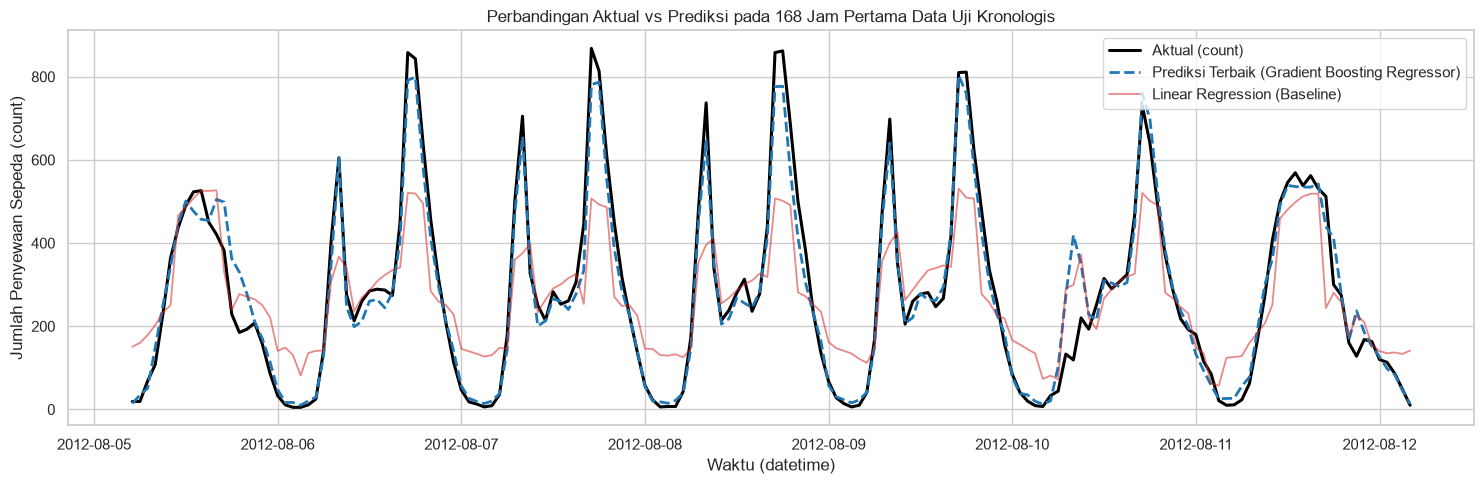

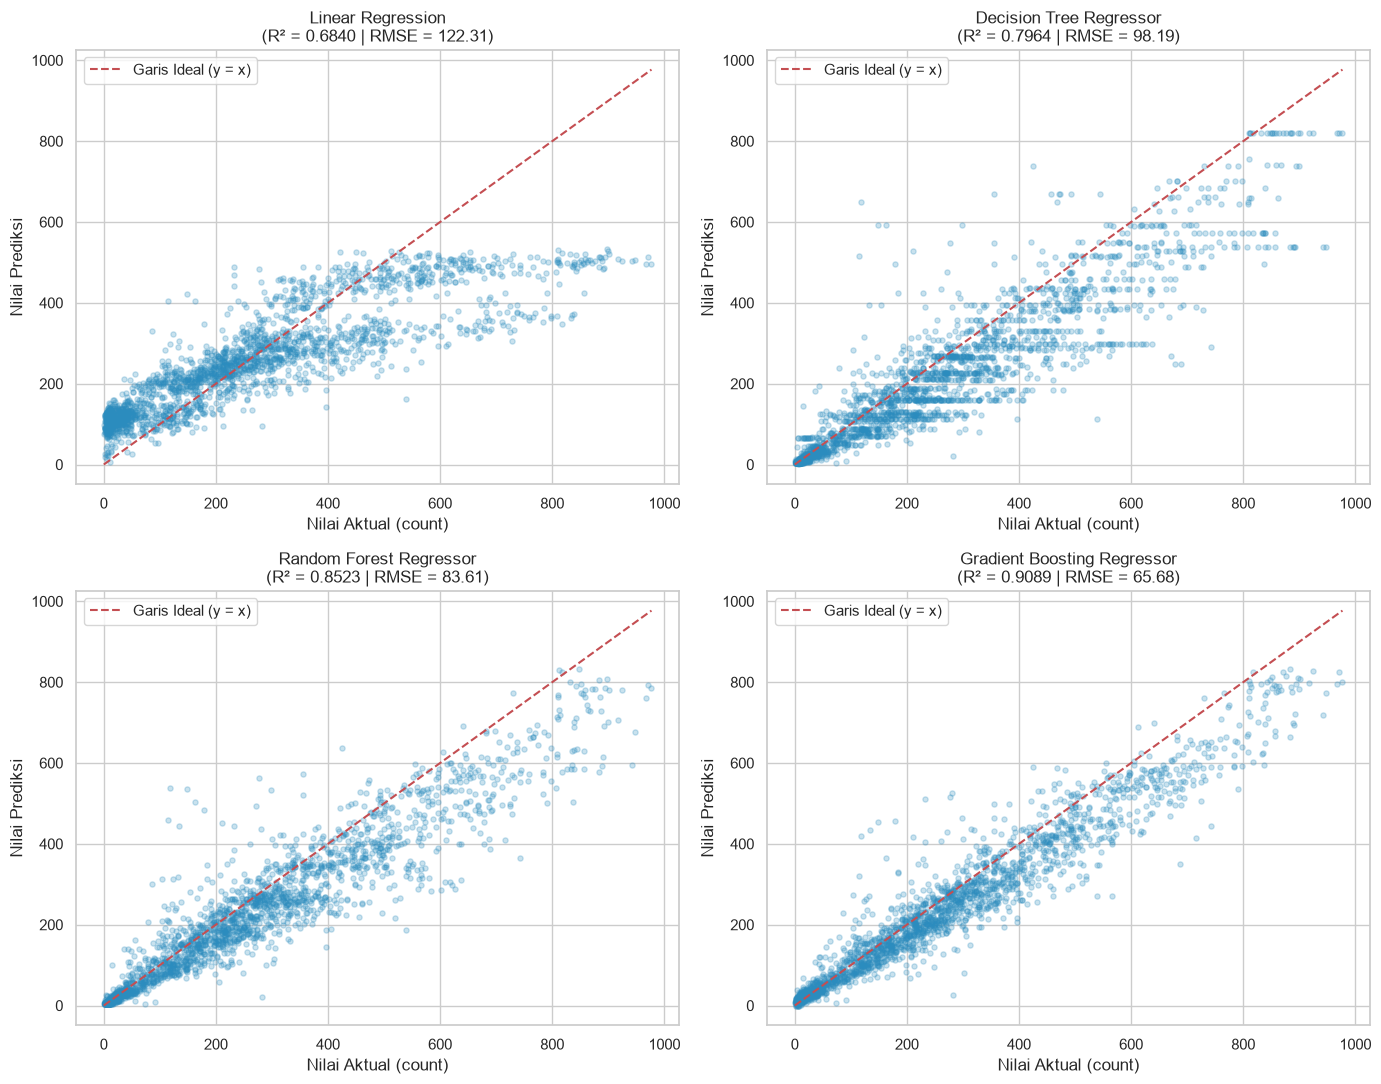

In [5]:
sample_compare = preds_df.copy()
sample_compare['Error_Best_Model'] = (sample_compare['actual'] - sample_compare[BEST_MODEL_NAME]).round(2)
for name in model_names:
    sample_compare[name] = sample_compare[name].round(2)
display(sample_compare.head(15))

# Grafik 1: Deret waktu 7 hari pertama (168 jam) pada periode uji
slice_df = preds_df.iloc[:168].copy()
plt.figure(figsize=(15, 5))
plt.plot(slice_df['datetime'], slice_df['actual'], label='Aktual (count)', color='black', linewidth=2.2)
plt.plot(slice_df['datetime'], slice_df[BEST_MODEL_NAME], label=f'Prediksi Terbaik ({BEST_MODEL_NAME})', color='#1f77b4', linestyle='--', linewidth=2)
plt.plot(slice_df['datetime'], slice_df['Linear Regression'], label='Linear Regression (Baseline)', color='#d62728', alpha=0.55, linewidth=1.3)
plt.title('Perbandingan Aktual vs Prediksi pada 168 Jam Pertama Data Uji Kronologis')
plt.xlabel('Waktu (datetime)')
plt.ylabel('Jumlah Penyewaan Sepeda (count)')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_timeseries_actual_vs_predicted.png', dpi=150)
plt.show()

# Grafik 2: Scatter Plot Aktual vs Prediksi untuk Keempat Algoritma
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()
max_val = max(preds_df['actual'].max(), preds_df[model_names].max().max())

for idx, name in enumerate(model_names):
    ax = axes[idx]
    r2_val = comparison_df.loc[comparison_df['Algorithm'] == name, 'R2'].values[0]
    rmse_val = comparison_df.loc[comparison_df['Algorithm'] == name, 'RMSE'].values[0]
    ax.scatter(preds_df['actual'], preds_df[name], alpha=0.25, s=14, color='#2b8cbe')
    ax.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Garis Ideal (y = x)')
    ax.set_title(f'{name}\n(R² = {r2_val:.4f} | RMSE = {rmse_val:.2f})')
    ax.set_xlabel('Nilai Aktual (count)')
    ax.set_ylabel('Nilai Prediksi')
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_scatter_actual_vs_predicted.png', dpi=150)
plt.show()

## 4. Residual Plot & Distribusi Error

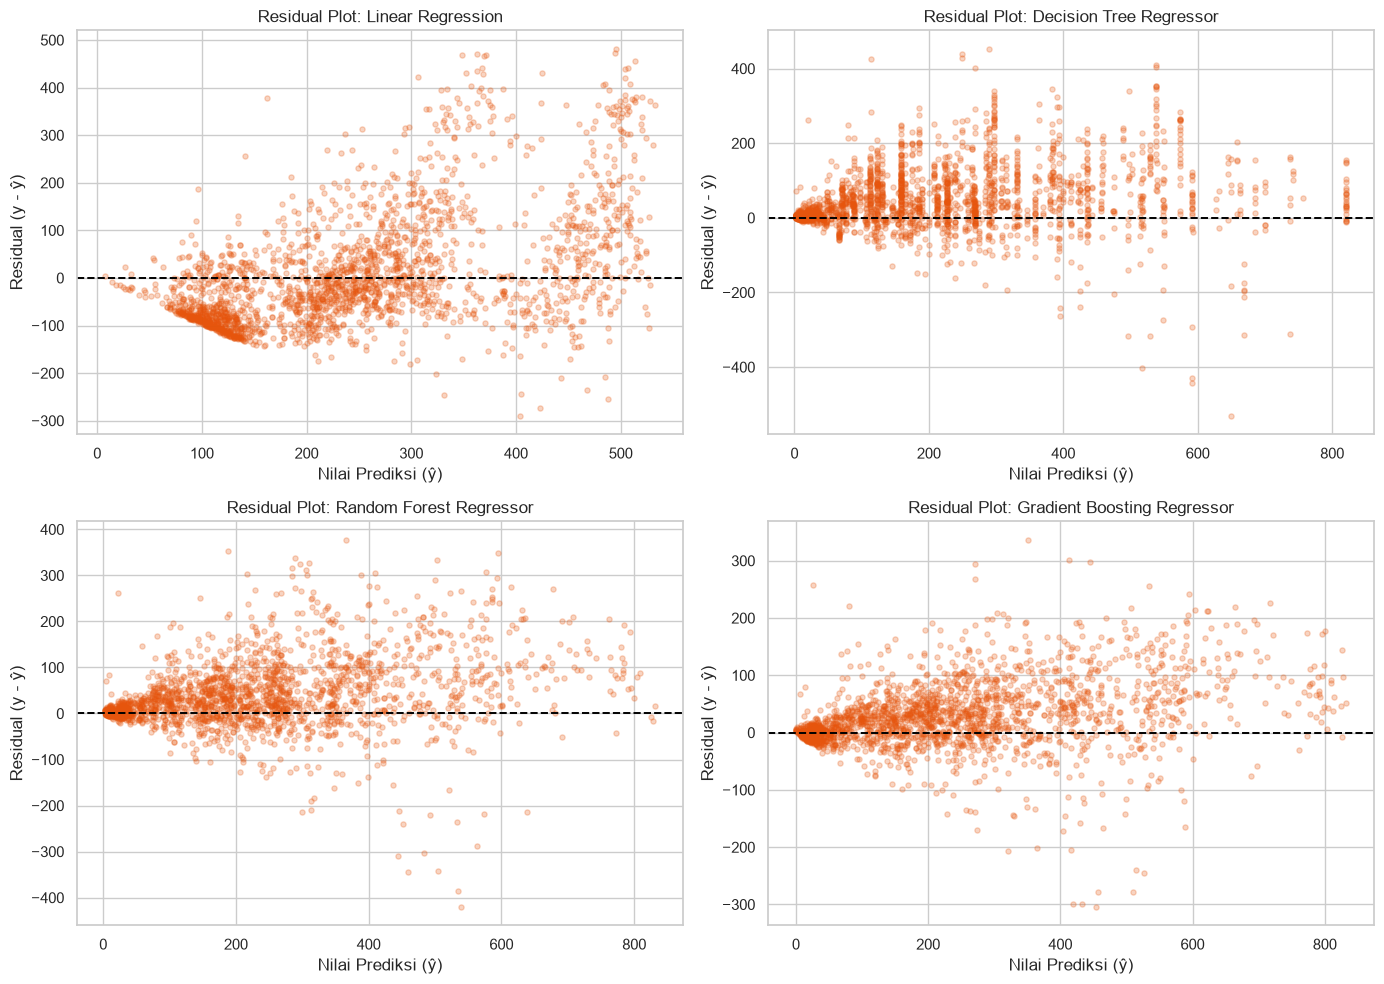

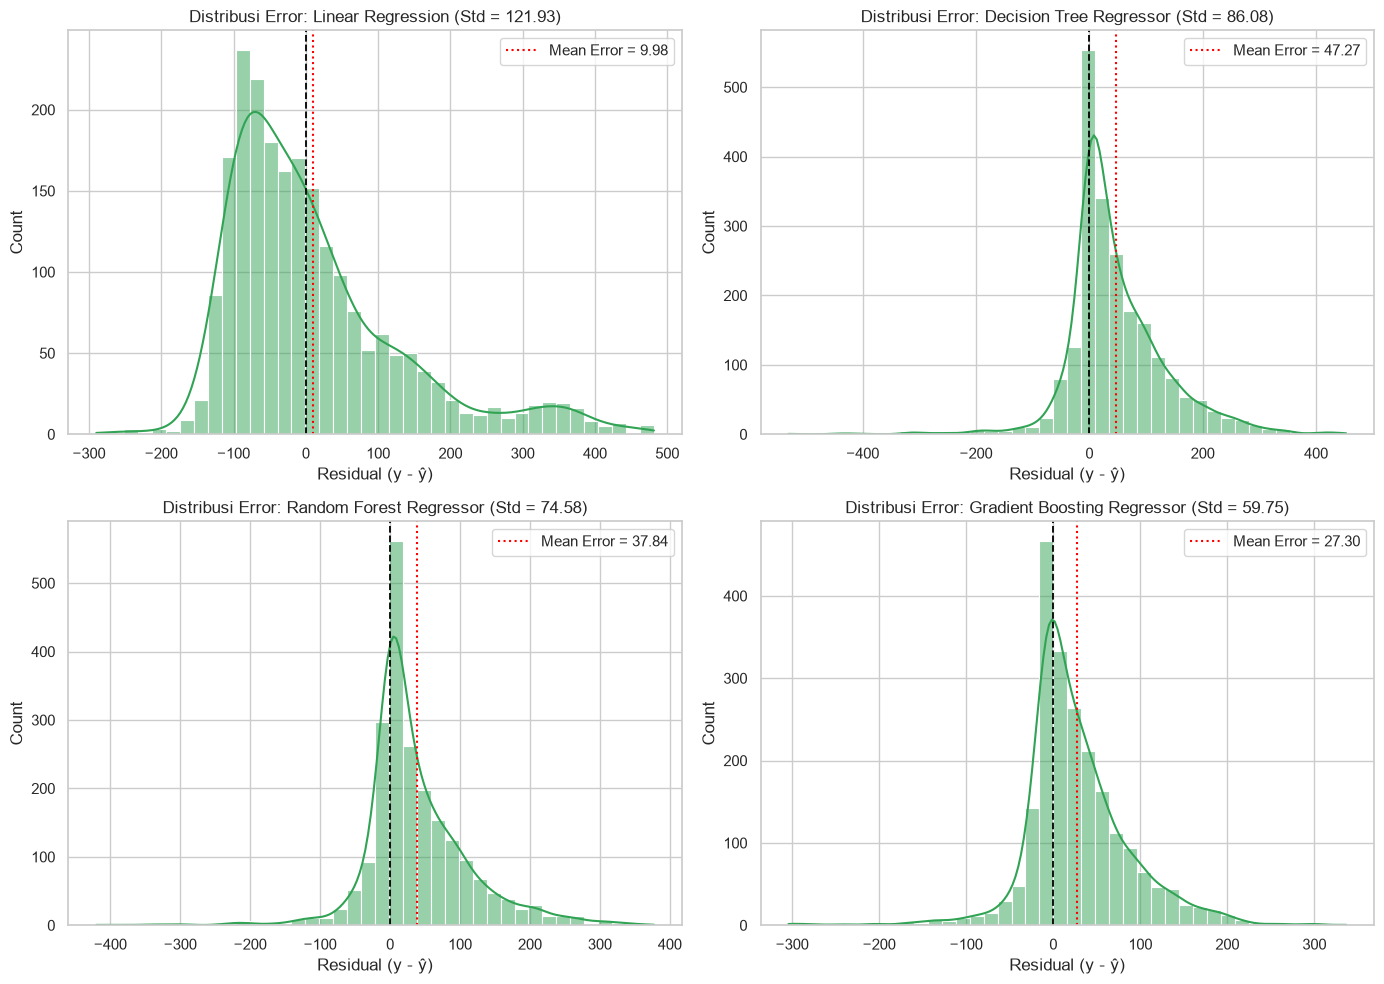

,Algorithm,Mean_Residual (Bias),Std_Residual
0,Linear Regression,9.98,121.93
1,Decision Tree Regressor,47.27,86.08
2,Random Forest Regressor,37.84,74.58
3,Gradient Boosting Regressor,27.30,59.75


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, name in enumerate(model_names):
    ax = axes[idx]
    residuals = preds_df['actual'] - preds_df[name]
    ax.scatter(preds_df[name], residuals, alpha=0.25, s=14, color='#e6550d')
    ax.axhline(0, color='black', linestyle='--', linewidth=1.4)
    ax.set_title(f'Residual Plot: {name}')
    ax.set_xlabel('Nilai Prediksi (ŷ)')
    ax.set_ylabel('Residual (y - ŷ)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_residual_plots.png', dpi=150)
plt.show()

# Distribusi Error (Histogram + KDE)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
error_stats = []

for idx, name in enumerate(model_names):
    ax = axes[idx]
    residuals = preds_df['actual'] - preds_df[name]
    mean_err = float(residuals.mean())
    std_err = float(residuals.std())
    error_stats.append({'Algorithm': name, 'Mean_Residual (Bias)': round(mean_err, 2), 'Std_Residual': round(std_err, 2)})
    sns.histplot(residuals, bins=40, kde=True, ax=ax, color='#31a354')
    ax.axvline(0, color='black', linestyle='--', linewidth=1.3)
    ax.axvline(mean_err, color='red', linestyle=':', linewidth=1.5, label=f'Mean Error = {mean_err:.2f}')
    ax.set_title(f'Distribusi Error: {name} (Std = {std_err:.2f})')
    ax.set_xlabel('Residual (y - ŷ)')
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_error_distributions.png', dpi=150)
plt.show()

display(pd.DataFrame(error_stats))

## 5. Evaluasi Performa Model Terbaik Berdasarkan Periode

--- Performa Model Terbaik Berdasarkan Jam (0-23) ---


,hour,Samples,Mean_Actual,Mean_Predicted,MAE,RMSE
0,0,90,75.38,63.65,19.12,37.69
1,1,90,46.17,39.19,15.59,23.37
2,2,90,28.73,30.99,11.01,14.75
3,3,89,14.70,17.90,6.67,8.23
4,4,90,9.19,16.41,8.29,9.74
5,5,91,29.48,27.36,9.00,11.46
6,6,91,105.49,92.07,26.60,31.39
7,7,91,295.77,263.64,54.19,73.74
8,8,91,502.74,440.97,93.96,118.08
9,9,91,298.36,287.22,40.95,54.73



--- Performa Model Terbaik Berdasarkan Tipe Hari ---


,Tipe_Hari,Samples,Mean_Actual,Mean_Predicted,MAE,RMSE
0,Akhir Pekan / Libur (0),715,247.51,230.13,43.66,63.22
1,Hari Kerja (1),1463,266.51,234.37,44.54,66.85



--- Performa Model Terbaik Berdasarkan Bulan Uji ---


,year_month,Samples,Mean_Actual,Mean_Predicted,MAE,RMSE
0,2012-08,355,284.54,277.89,36.18,58.25
1,2012-09,456,292.60,273.03,44.97,62.99
2,2012-10,456,280.51,242.60,54.93,81.24
3,2012-11,455,231.98,196.73,42.37,61.52
4,2012-12,456,217.05,184.50,41.00,60.16


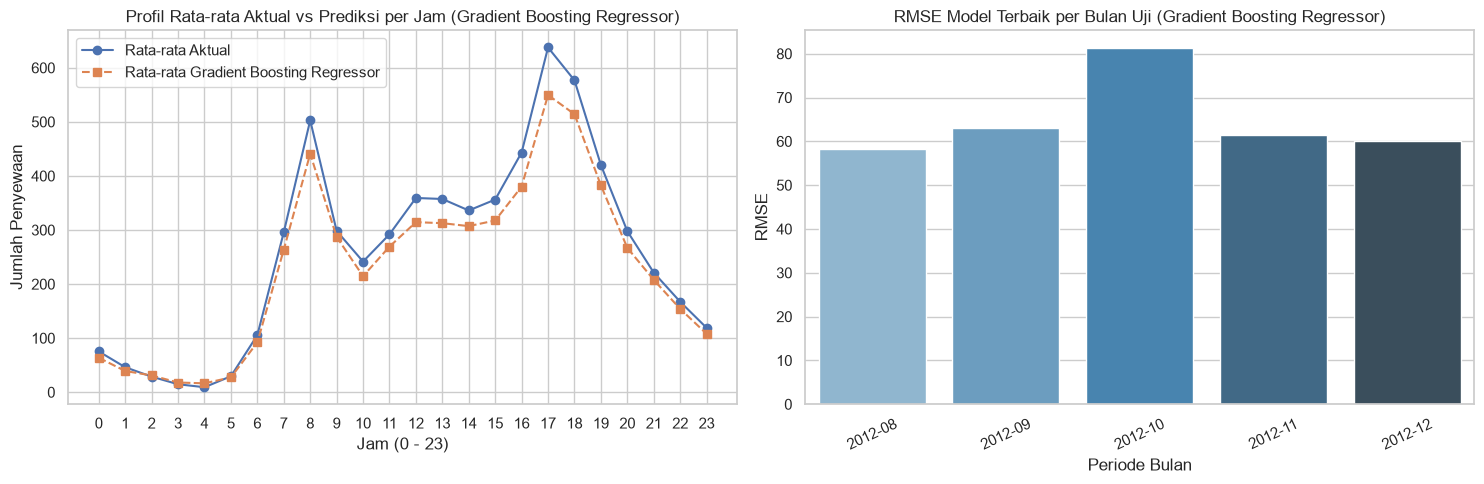

In [7]:
eval_period_df = preds_df.merge(
    cleaned_df[['datetime', 'hour', 'workingday', 'season', 'weather', 'year', 'month']],
    on='datetime',
    how='left'
)
eval_period_df['abs_error'] = np.abs(eval_period_df['actual'] - eval_period_df[BEST_MODEL_NAME])
eval_period_df['sq_error'] = (eval_period_df['actual'] - eval_period_df[BEST_MODEL_NAME]) ** 2
eval_period_df['year_month'] = eval_period_df['datetime'].dt.to_period('M').astype(str)

# 5A. Performa per Jam (0 - 23)
hourly_perf = eval_period_df.groupby('hour').agg(
    Samples=('actual', 'count'),
    Mean_Actual=('actual', 'mean'),
    Mean_Predicted=(BEST_MODEL_NAME, 'mean'),
    MAE=('abs_error', 'mean'),
    RMSE=('sq_error', lambda s: np.sqrt(np.mean(s)))
).round(2).reset_index()

print('--- Performa Model Terbaik Berdasarkan Jam (0-23) ---')
display(hourly_perf)

# 5B. Performa Berdasarkan Hari Kerja vs Akhir Pekan/Libur
workday_perf = eval_period_df.groupby('workingday').agg(
    Samples=('actual', 'count'),
    Mean_Actual=('actual', 'mean'),
    Mean_Predicted=(BEST_MODEL_NAME, 'mean'),
    MAE=('abs_error', 'mean'),
    RMSE=('sq_error', lambda s: np.sqrt(np.mean(s)))
).round(2).reset_index()
workday_perf['Tipe_Hari'] = workday_perf['workingday'].map({0: 'Akhir Pekan / Libur (0)', 1: 'Hari Kerja (1)'})
print('\n--- Performa Model Terbaik Berdasarkan Tipe Hari ---')
display(workday_perf[['Tipe_Hari', 'Samples', 'Mean_Actual', 'Mean_Predicted', 'MAE', 'RMSE']])

# 5C. Performa Berdasarkan Bulan Uji
monthly_perf = eval_period_df.groupby('year_month').agg(
    Samples=('actual', 'count'),
    Mean_Actual=('actual', 'mean'),
    Mean_Predicted=(BEST_MODEL_NAME, 'mean'),
    MAE=('abs_error', 'mean'),
    RMSE=('sq_error', lambda s: np.sqrt(np.mean(s)))
).round(2).reset_index()
print('\n--- Performa Model Terbaik Berdasarkan Bulan Uji ---')
display(monthly_perf)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(hourly_perf['hour'], hourly_perf['Mean_Actual'], marker='o', label='Rata-rata Aktual')
axes[0].plot(hourly_perf['hour'], hourly_perf['Mean_Predicted'], marker='s', linestyle='--', label=f'Rata-rata {BEST_MODEL_NAME}')
axes[0].set_title(f'Profil Rata-rata Aktual vs Prediksi per Jam ({BEST_MODEL_NAME})')
axes[0].set_xlabel('Jam (0 - 23)')
axes[0].set_ylabel('Jumlah Penyewaan')
axes[0].set_xticks(range(0, 24))
axes[0].legend()

sns.barplot(data=monthly_perf, x='year_month', y='RMSE', ax=axes[1], hue='year_month', palette='Blues_d', legend=False)
axes[1].set_title(f'RMSE Model Terbaik per Bulan Uji ({BEST_MODEL_NAME})')
axes[1].set_xlabel('Periode Bulan')
axes[1].set_ylabel('RMSE')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_periodic_performance.png', dpi=150)
plt.show()

## 6. Analisis Kelebihan dan Kekurangan Setiap Model

1. **Linear Regression**
   - *Kelebihan:* Waktu pelatihan sangat cepat, koefisien mudah diinterpretasikan secara linear, dan tidak rentan *overfitting* pada data berdimensi rendah.
   - *Kekurangan:* Tidak mampu menangkap interaksi non-linear yang kompleks antara jam sibuk (`hour`), status hari kerja (`workingday`), dan cuaca (`weather`), sehingga menghasilkan error (MAE/RMSE) paling besar dan $R^2$ paling rendah.

2. **Decision Tree Regressor**
   - *Kelebihan:* Mampu memodelkan hubungan non-linear serta aturan interaksi fitur (misalnya perbedaan jam sibuk pagi/sore pada hari kerja vs siang hari pada akhir pekan) tanpa perlu asumsi distribusi.
   - *Kekurangan:* Pohon keputusan tunggal memiliki varians tinggi (*high variance*), menghasilkan prediksi bertingkat (*step-function*), dan kurang halus saat melakukan generalisasi ke periode waktu masa depan.

3. **Random Forest Regressor**
   - *Kelebihan:* Mengurangi varians secara signifikan dibanding Decision Tree tunggal melalui agregasi *bagging* banyak pohon keputusan, tahan terhadap *outlier* meteorologi, dan memberikan skor $R^2$ tinggi.
   - *Kekurangan:* Ukuran file model lebih besar dan proses pelatihan/inferensi lebih berat dibanding model linear maupun boosting dengan jumlah estimator setara.

4. **Gradient Boosting Regressor**
   - *Kelebihan:* Membangun pohon secara sekuensial untuk memperbaiki error residual tahap sebelumnya, mampu menangkap pola interaksi temporal-cuaca secara presisi, dan sangat kompetitif pada data tabular.
   - *Kekurangan:* Memerlukan penyetelan *hyperparameter* (`learning_rate`, `max_depth`, `n_estimators`) yang cermat agar tidak *overfitting* terhadap tren historis.

## 7. Penyimpanan Model Terpilih & Artefak Evaluasi Final

In [8]:
# 1. Simpan model terlatih terbaik ke artifacts/demand_model.joblib
demand_model_path = ARTIFACTS_DIR / 'demand_model.joblib'
joblib.dump(best_estimator, demand_model_path)

# 2. Pastikan preprocessing_pipeline.joblib tersimpan
pipeline_path = ARTIFACTS_DIR / 'preprocessing_pipeline.joblib'
joblib.dump(preprocessing_pipeline, pipeline_path)

# 3. Perbarui feature_config.json dengan informasi model terpilih
feature_config['selected_model_name'] = BEST_MODEL_NAME
feature_config['model_artifact'] = 'artifacts/demand_model.joblib'
feature_config['pipeline_artifact'] = 'artifacts/preprocessing_pipeline.joblib'
feature_config_path = ARTIFACTS_DIR / 'feature_config.json'
with open(feature_config_path, 'w', encoding='utf-8') as f:
    json.dump(feature_config, f, indent=2)

# 4. Simpan hasil evaluasi lengkap ke artifacts/model_metrics.json
model_metrics = {
    'evaluated_at': datetime.now().isoformat(timespec='seconds'),
    'selection_criterion': 'Lowest RMSE and MAE on Chronological Test Split (20% latest observations)',
    'best_model': BEST_MODEL_NAME,
    'best_metrics': {
        'MAE': float(best_model_row['MAE']),
        'RMSE': float(best_model_row['RMSE']),
        'R2': float(best_model_row['R2']),
        'RMSLE': float(best_model_row['RMSLE']),
        'Training_Time_Sec': best_model_row['Training_Time_Sec']
    },
    'algorithms': comparison_df.to_dict(orient='records'),
    'periodic_performance': {
        'by_workday': workday_perf[['Tipe_Hari', 'Samples', 'Mean_Actual', 'Mean_Predicted', 'MAE', 'RMSE']].to_dict(orient='records'),
        'by_month': monthly_perf.to_dict(orient='records')
    }
}

metrics_path = ARTIFACTS_DIR / 'model_metrics.json'
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(model_metrics, f, indent=2)

print('=== ARTEFAK FINAL BERHASIL DISIMPAN ===')
print(f'1. Model Terlatih   : {demand_model_path}')
print(f'2. Pipeline         : {pipeline_path}')
print(f'3. Feature Config   : {feature_config_path}')
print(f'4. Model Metrics    : {metrics_path}')

=== ARTEFAK FINAL BERHASIL DISIMPAN ===
1. Model Terlatih   : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\demand_model.joblib
2. Pipeline         : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\preprocessing_pipeline.joblib
3. Feature Config   : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\feature_config.json
4. Model Metrics    : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\model_metrics.json
